# Лабораторная работа №9. Бинарная (логистическая) регрессия

**Дисциплина:** Введение в анализ больших данных

**Данные:** `datlg.csv` — медицинские данные по кардиологии.  
`y` — зависимая переменная (стоит делать операцию пациенту или нет).  
Предикторы: `sex`, `x1`, `x2`, `x3`, `x4`.

$$
P(Y=1 \mid x) = \frac{1}{1 + \exp(-(b_0 + b_1 x_1 + \ldots + b_k x_k))}
$$


## 0. Импорт


In [2]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, accuracy_score, classification_report,
    roc_curve, roc_auc_score, ConfusionMatrixDisplay,
)

plt.rcParams["figure.figsize"] = (10, 6)
sns.set_style("whitegrid")
np.random.seed(42)


---
## 1. Данные

Это учебный датасет по кардиологии — задача бинарной классификации: стоит ли делать пациенту операцию на основе имеющихся предикторов

Отклик `y`: 0/1 — делать операцию или нет.  
Предикторы — бинарные признаки `sex`, `x1`–`x4`.


In [ ]:
df = pd.read_csv("datlg.csv", index_col=0)
print(df.head())
print("\ny:")
print(df["y"].value_counts())
print("\nДоля y=1: {:.3f}".format(df["y"].mean())) # 104 : 303


   y  sex  x1  x2  x3  x4
1  0    0   1   0   0   0
2  0    0   0   1   0   1
3  0    0   0   1   1   0
4  0    1   0   1   1   0
5  1    1   0   0   0   0

y:
y
0    199
1    104
Name: count, dtype: int64

Доля y=1: 0.343


---
## 2. Логит-модель

Логистическая регрессия — это модель для предсказания вероятности бинарного события (да/нет, 0/1, болен/здоров)

`smf.logit("y ~ x1 + x2 + ...", data=df).fit()`


In [24]:
m_logit = smf.logit(
    "y ~ sex + x1 + x2 + x3 + x4",
    data=df,
).fit(disp=False)
print(m_logit.summary())

# Какие признаки значимы? Правило простое: если P>|z| меньше 0.05, признак значим (влияет на результат). Если больше — незначим

# Коэффициенты "coef" показывают, как меняется шанс (логарифм шанса) операции
    # x2 (coef = +1.8963): Знак плюс. Это значит, что наличие/увеличение x2 сильно повышает вероятность операции.
    # x4 (coef = +0.6167), x3 (coef = +0.7756): Тоже повышают шанс, но они незначимы.
    # x1 (coef = -1.8631): Знак минус. Наличие x1 снижает вероятность операции (при прочих равных).
    # sex (coef = -0.5358): Отрицательный (снижает), но незначим

# LLR p-value = 3.364e-12: Это главный показатель значимости модели. Он намного меньше 0.05 (и даже меньше 0.001). 
    # Это значит, что модель статистически значима в целом. Факторы sex, x1, x2, x3, x4 вместе действительно помогают предсказывать y (делать операцию или нет)

# Псевдо-R-квадрат (около 16%). В логистической регрессии он редко бывает высоким (как 0.8 в линейной). 
    # Значение 0.16 говорит о том, что модель объясняет часть данных, но предсказательная сила у нее умеренная

# std err — это мера неопределённости нашей оценки (насколько сильно точечная оценка (столбец coef) может «гулять» от выборки к выборке). Она зависит от:
    # Разброса данных — если данные «шумные», ошибка больше.
    # Размера выборки — чем больше наблюдений (n), тем меньше ошибка (растёт точность).
    # Корреляций между признаками — мультиколлинеарность увеличивает ошибки


                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                  303
Model:                          Logit   Df Residuals:                      297
Method:                           MLE   Df Model:                            5
Date:                Tue, 20 Oct 2026   Pseudo R-squ.:                  0.1609
Time:                        11:11:56   Log-Likelihood:                -163.53
converged:                       True   LL-Null:                       -194.88
Covariance Type:            nonrobust   LLR p-value:                 3.364e-12
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.6332      0.253     -2.500      0.012      -1.130      -0.137
sex           -0.5358      0.290     -1.849      0.064      -1.104       0.032
x1            -1.8631      0.749     -2.489      0.0

### Пробит-модель

особо не используется, но знать обязаны. 

Тот же набор предикторов, другая link-функция.


In [25]:
m_probit = smf.probit(
    "y ~ sex + x1 + x2 + x3 + x4",
    data=df,
).fit(disp=False)
print(m_probit.summary().tables[1])
print(f"\nAIC logit = {m_logit.aic:.3f}, AIC probit = {m_probit.aic:.3f}") 

# AIC (информационный критерий Акаике) — это метрика «качества» модели. Чем меньше — тем лучше 
    # (она штрафует модель за лишнюю сложность и награждает за хорошую предсказательную способность)
        # У логита AIC = 339.057
        # У пробита AIC = 339.712
    # Разница крошечная (меньше единицы), но победил Логит (у него AIC чуть меньше). для наших  данных логистическая регрессия подходит математически чутка лучше


                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.3939      0.153     -2.574      0.010      -0.694      -0.094
sex           -0.3157      0.173     -1.825      0.068      -0.655       0.023
x1            -0.9762      0.354     -2.761      0.006      -1.669      -0.283
x2             1.1431      0.224      5.110      0.000       0.705       1.582
x3             0.4308      0.249      1.730      0.084      -0.057       0.919
x4             0.3567      0.261      1.369      0.171      -0.154       0.867

AIC logit = 339.057, AIC probit = 339.712


### Значимость модели в целом (likelihood-ratio)


In [26]:
lr = 2 * (m_logit.llf - m_logit.llnull)
p_lr = stats.chi2.sf(lr, m_logit.df_model)
print(f"LR chi2 = {lr:.2f}, df = {m_logit.df_model:.0f}, p = {p_lr:.4e}")
print("модель значима" if p_lr < 0.05 else "модель не значима")


LR chi2 = 62.70, df = 5, p = 3.3645e-12
модель значима


---
## 3. Матрица неточностей

Порог по умолчанию: 0.5.

| | прогноз 0 | прогноз 1 |
|--|-----------|-----------|
| факт 0 | TN | FP |
| факт 1 | FN | TP |

- **Accuracy** = (TP+TN)/N  
- **Sensitivity (Recall)** = TP/(TP+FN)  
- **Specificity** = TN/(TN+FP)


Confusion matrix:
 [[184  15]
 [ 61  43]]
Accuracy = 0.7492
              precision    recall  f1-score   support

           0      0.751     0.925     0.829       199
           1      0.741     0.413     0.531       104

    accuracy                          0.749       303
   macro avg      0.746     0.669     0.680       303
weighted avg      0.748     0.749     0.727       303



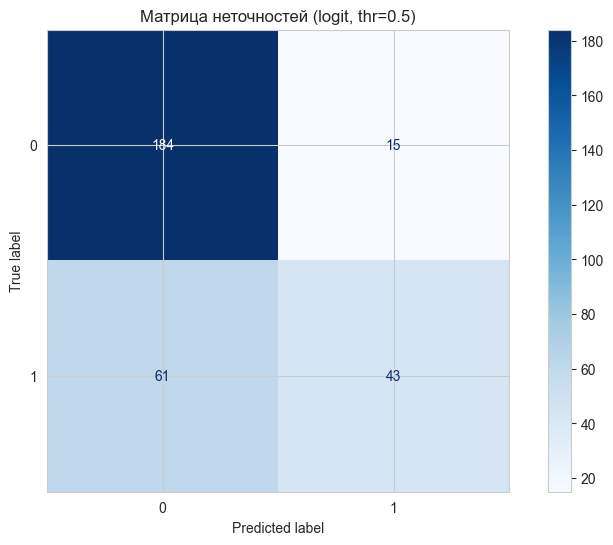

In [30]:
prob = m_logit.predict(df)
pred = (prob >= 0.5).astype(int)

# (prob >= 0.5) - проверка условия
    # 0.91 >= 0.5 → True
    # 0.05 >= 0.5 → False

    # можно поставить 0.3 проба, модель будет назначать операцию уже при вероятности 30% и выше. 
    # Это повысит чувствительность (поймаем больше больных), но снизит специфичность (появится больше ложных тревог).
         # Ложная тревога (False Positive, FP) — это случай, когда модель предсказала 1 («операция нужна»), а на самом деле 0 («операция не нужна»). 
         # То есть модель «подняла тревогу», а больной на самом деле здоров.

         # Метрики, которые измеряют ложные тревоги - в телеграм конспектах

cm = confusion_matrix(df["y"], pred)
print("Confusion matrix:\n", cm)
print("Accuracy =", round(accuracy_score(df["y"], pred), 4))
print(classification_report(df["y"], pred, digits=3, zero_division=0))

# Логистическая регрессия (в отличие от деревьев решений) никогда не выдает классы 0 или 1 напрямую. Она всегда выдает вероятность (число с плавающей точкой)
    # Но чтобы посчитать Accuracy, Sensitivity и построить матрицу неточностей, нам нужны жесткие ответы: «болен» или «здоров».

ConfusionMatrixDisplay(cm, display_labels=[0, 1]).plot(cmap="Blues")
plt.title("Матрица неточностей (logit, thr=0.5)")
plt.show()

# комментарии следующие:
    # Сейчас в коде стоит жесткий порог: prob >= 0.5. То есть модель говорит «операция нужна», только если вероятность больше 50%.
    # Решение: Порог можно снизить (например, до 0.3). Тогда модель будет смелее назначать операции.
    # Что будет: Она найдет гораздо больше тех, кому нужна операция (Sensitivity вырастет).
    # Цена: Она чаще будет ошибаться и отправлять на операцию тех, кому она не нужна (Specificity упадет).
    # В медицинских задачах порог почти всегда подбирают под клинические нужды, смещая его в сторону чувствительности (чтобы не упустить больных).


## проведем рубрику "эксперименты"

In [31]:
from sklearn.metrics import confusion_matrix

# ВАЖНО: берем только вероятности в виде массива, чтобы не было глюков
probs = m_logit.predict(df).values 
y_true = df["y"].values

print(f"{'Порог':<6} | {'Поймали':<8} | {'Пропустили':<10} | {'Лож.тревоги':<11} | {'Sens(Recall)':<12} | {'Spec':<6}")
print("-" * 75)

# Перебираем разные пороги
for thr in [0.30, 0.35, 0.40, 0.43, 0.50]:
    preds = (probs >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, preds).ravel()
    
    sens = tp / (tp + fn)
    spec = tn / (tn + fp)
    
    print(f"{thr:<6.2f} | {tp:<8} | {fn:<10} | {fp:<11} | {sens:<12.3f} | {spec:<6.3f}")

Порог  | Поймали  | Пропустили | Лож.тревоги | Sens(Recall) | Spec  
---------------------------------------------------------------------------
0.30   | 74       | 30         | 62          | 0.712        | 0.688 
0.35   | 55       | 49         | 29          | 0.529        | 0.854 
0.40   | 50       | 54         | 22          | 0.481        | 0.889 
0.43   | 44       | 60         | 17          | 0.423        | 0.915 
0.50   | 43       | 61         | 15          | 0.413        | 0.925 


---
## 4. ROC-кривая и AUC

# Логистическая регрессия выдаёт вероятность p ∈ [0, 1], а не готовый класс 0/1. Чтобы получить класс, нужно выбрать порог (в ноутбуке — 0.5).
    # Но порог можно двигать: 0.3, 0.7, 0.9…
# Вопрос: а как оценивать качество модели независимо от конкретного порога? (насколько хорошо она вообще ранжирует пациентов по вероятности «нужна операция»?)

Чем ближе кривая к верхнему левому углу и чем больше **AUC**, тем лучше.  
AUC ≈ 0.5 — как случайное угадывание; ближе к 1 — сильная модель.


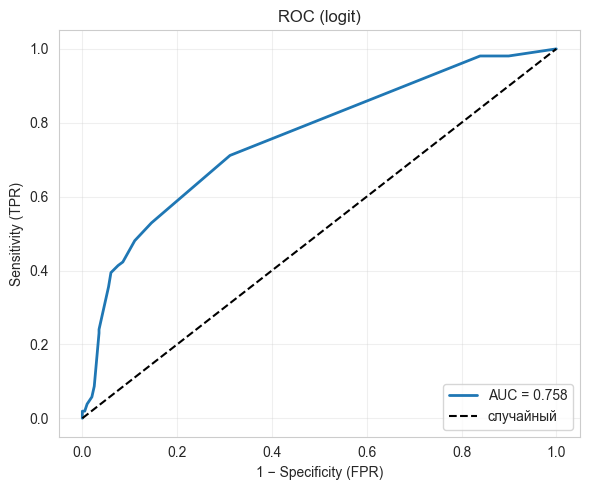

AUC = 0.7579


In [13]:
fpr, tpr, _ = roc_curve(df["y"], prob)
auc = roc_auc_score(df["y"], prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, lw=2, label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], "k--", label="случайный")
plt.xlabel("1 − Specificity (FPR)")
plt.ylabel("Sensitivity (TPR)")
plt.title("ROC (logit)")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print(f"AUC = {auc:.4f}")

# Кривая делает резкий скачок вверх в самом начале (примерно до FPR = 0.1, TPR = 0.4).
    # Это значит: если мы выберем очень высокий порог, модель почти не будет ошибочно тревожить здоровых (FPR низкий), но при этом сможет поймать около
        #  40% действительно больных (Sensitivity = 0.4).
    # Дальше кривая идёт более полого. Чтобы поймать, скажем, 80% больных (TPR = 0.8), нам придётся смириться с тем, что мы «поднимем тревогу» примерно
        #  у 50% здоровых (FPR = 0.5)


---
## 5. Train / test

Правильный порядок: обучить на train, оценить на **test** (и при желании на train для сравнения).


In [18]:
train, test = train_test_split(
    df, test_size=0.3, random_state=7, stratify=df["y"]
)
print("train:", train.shape, "test:", test.shape)
print("доля y=1 train:", round(train["y"].mean(), 3))
print("доля y=1 test :", round(test["y"].mean(), 3))


train: (212, 6) test: (91, 6)
доля y=1 train: 0.344
доля y=1 test : 0.341


In [32]:
model = smf.logit(
    "y ~ sex + x1 + x2 + x3 + x4",
    data=train,
).fit(disp=False)
print(model.summary().tables[1])


                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.6376      0.295     -2.162      0.031      -1.216      -0.060
sex           -0.5149      0.340     -1.514      0.130      -1.181       0.152
x1            -2.1653      1.040     -2.083      0.037      -4.203      -0.127
x2             1.7827      0.436      4.093      0.000       0.929       2.636
x3             0.3475      0.511      0.680      0.496      -0.654       1.349
x4             1.2895      0.605      2.132      0.033       0.104       2.475


In [33]:
def evaluate(model, data, name):
    y = data["y"]
    p = model.predict(data)
    yhat = (p >= 0.5).astype(int)
    acc = accuracy_score(y, yhat)
    auc = roc_auc_score(y, p)
    cm = confusion_matrix(y, yhat)
    tn, fp, fn, tp = cm.ravel()
    sens = tp / (tp + fn) if (tp + fn) else np.nan
    spec = tn / (tn + fp) if (tn + fp) else np.nan
    print(f"=== {name} ===")
    print("CM:\n", cm)
    print(f"Accuracy = {acc:.4f}, Sensitivity = {sens:.4f}, "
          f"Specificity = {spec:.4f}, AUC = {auc:.4f}")
    print(classification_report(y, yhat, digits=3, zero_division=0))
    return p, auc

p_tr, auc_tr = evaluate(model, train, "TRAIN")
p_te, auc_te = evaluate(model, test, "TEST")


=== TRAIN ===
CM:
 [[126  13]
 [ 40  33]]
Accuracy = 0.7500, Sensitivity = 0.4521, Specificity = 0.9065, AUC = 0.7534
              precision    recall  f1-score   support

           0      0.759     0.906     0.826       139
           1      0.717     0.452     0.555        73

    accuracy                          0.750       212
   macro avg      0.738     0.679     0.690       212
weighted avg      0.745     0.750     0.733       212

=== TEST ===
CM:
 [[52  8]
 [17 14]]
Accuracy = 0.7253, Sensitivity = 0.4516, Specificity = 0.8667, AUC = 0.7473
              precision    recall  f1-score   support

           0      0.754     0.867     0.806        60
           1      0.636     0.452     0.528        31

    accuracy                          0.725        91
   macro avg      0.695     0.659     0.667        91
weighted avg      0.714     0.725     0.712        91



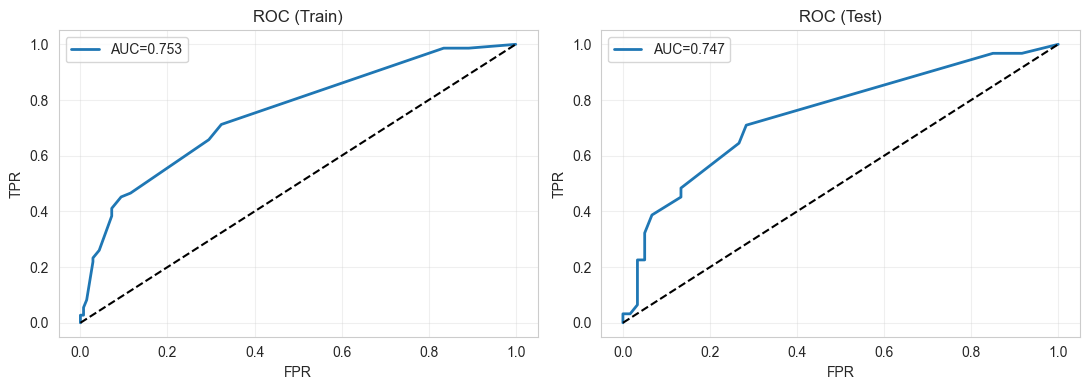

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, data, p, title, auc_v in [
    (axes[0], train, p_tr, "Train", auc_tr),
    (axes[1], test, p_te, "Test", auc_te),
]:
    fpr, tpr, _ = roc_curve(data["y"], p)
    ax.plot(fpr, tpr, lw=2, label=f"AUC={auc_v:.3f}")
    ax.plot([0, 1], [0, 1], "k--")
    ax.set_title(f"ROC ({title})")
    ax.set_xlabel("FPR")
    ax.set_ylabel("TPR")
    ax.legend()
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


---
## 6. Кросс-валидация (Stratified K-Fold)

Для устойчивой оценки качества модели используем 5-блочную стратифицированную кросс-валидацию через `sklearn`.  
Считаем **accuracy** и **AUC** на каждом фолде, затем усредняем.


In [35]:
X = df[["sex", "x1", "x2", "x3", "x4"]]
y = df["y"]

sk_model = LogisticRegression(max_iter=1000)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

acc_scores = cross_val_score(sk_model, X, y, cv=cv, scoring="accuracy")
auc_scores = cross_val_score(sk_model, X, y, cv=cv, scoring="roc_auc")

print("Accuracy по фолдам:", np.round(acc_scores, 4))
print(f"Accuracy: {acc_scores.mean():.4f} ± {acc_scores.std():.4f}")
print("AUC по фолдам    :", np.round(auc_scores, 4))
print(f"AUC:      {auc_scores.mean():.4f} ± {auc_scores.std():.4f}")

# Средняя Accuracy составила 0.733 ± 0.046, средняя AUC — 0.739 ± 0.067. Полученные значения близки к результатам на отложенной 
    # тестовой выборке (0.725 и 0.747), что подтверждает отсутствие переобучения и стабильность модели. 
    # Небольшой разброс метрик между фолдами (от 0.68 до 0.82) объясняется малым размером выборки и естественной 
    # вариативностью медицинских данных. В целом модель показывает приемлемое качество для бинарной классификации»


Accuracy по фолдам: [0.7213 0.7213 0.8197 0.7167 0.6833]
Accuracy: 0.7325 ± 0.0459
AUC по фолдам    : [0.7405 0.6958 0.8673 0.6862 0.7045]
AUC:      0.7389 ± 0.0668


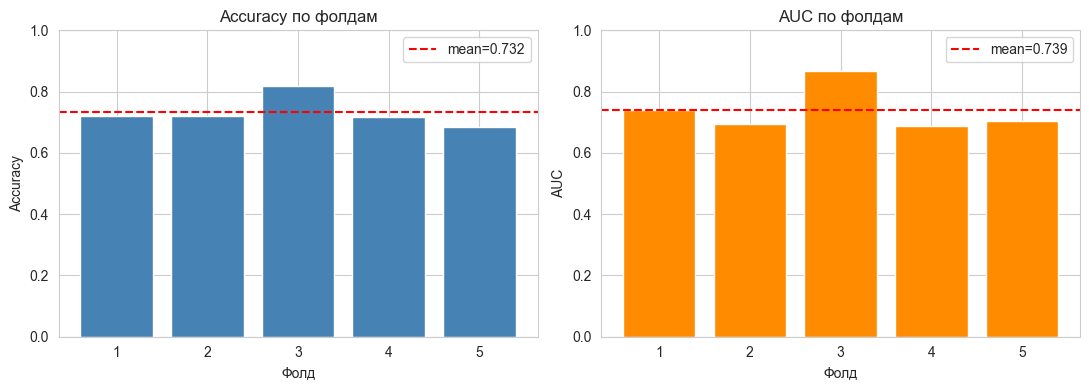

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(range(1, 6), acc_scores, color="steelblue")
ax[0].axhline(acc_scores.mean(), color="red", ls="--", label=f"mean={acc_scores.mean():.3f}")
ax[0].set_title("Accuracy по фолдам")
ax[0].set_xlabel("Фолд")
ax[0].set_ylabel("Accuracy")
ax[0].set_ylim(0, 1)
ax[0].legend()

ax[1].bar(range(1, 6), auc_scores, color="darkorange")
ax[1].axhline(auc_scores.mean(), color="red", ls="--", label=f"mean={auc_scores.mean():.3f}")
ax[1].set_title("AUC по фолдам")
ax[1].set_xlabel("Фолд")
ax[1].set_ylabel("AUC")
ax[1].set_ylim(0, 1)
ax[1].legend()
plt.tight_layout()
plt.show()


### Описание результатов

1. Значимость коэффициентов (p < 0.05) и знак связи.  
2. Метрики на **train** и **test** (accuracy, sensitivity, specificity, AUC).  
3. Нет ли сильного проседания на test (переобучение).  
4. Форма ROC и величина AUC (ориентиры: >0.7 приемлемо, >0.8 хорошо).  
5. Кросс-валидация: среднее ± std по фолдам — оценка устойчивости модели.

